<a href="https://colab.research.google.com/github/ishikabeniwal/CSET343/blob/main/Assignment8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
!pip install nltk
import pandas as pd
import nltk
import re

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('punkt')
nltk.download('punkt_tab')

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Load dataset (upload CSV to Colab first)
df = pd.read_csv('/content/Patient_Safety_Perspective_Headlines.csv')

print(df.head())
print(df.columns)

               Date                         Source  \
0    December 2003       Medscape General Medicine   
1    December 2003       Medscape General Medicine   
2      August 2003   Medscape Business of Medicine   
3    November 2002       Medscape General Medicine   
4     October 2002           Medscape Med Students   

                                           Headlines  \
0  Improving the Quality of Care in Physician Off...   
1        Uninvited, Unwelcome Medical Email Messages   
2       One Hospital's Journey Toward Patient Safety   
3                                             Bodies   
4                              Lessons From the PICU   

                                              Teaser  
0  Could the greatest barrier to quality improvem...  
1  Are medical spam messages potentially harmful ...  
2  In response to the Institute of Medicine repor...  
3  A first-time novelist examines corruption, sca...  
4  A newly minted intern finds out how little he ...  
Index(['

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [8]:
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'[^a-z\s]', '', text)
    words = nltk.word_tokenize(text)

    words = [
        lemmatizer.lemmatize(w)
        for w in words if w not in stop_words
    ]
    return words
print(df.columns)

df['cleaned'] = df['Headlines'].apply(clean_text)

print(df['cleaned'].head())

Index(['Date', 'Source', 'Headlines', 'Teaser'], dtype='object')
0    [improving, quality, care, physician, office, ...
1      [uninvited, unwelcome, medical, email, message]
2    [one, hospital, journey, toward, patient, safety]
3                                               [body]
4                                       [lesson, picu]
Name: cleaned, dtype: object


[('patient', 157), ('drug', 69), ('physician', 57), ('new', 53), ('malpractice', 51), ('risk', 50), ('doctor', 44), ('error', 42), ('care', 41), ('safety', 41), ('report', 40), ('nurse', 37), ('medical', 34), ('cancer', 27), ('get', 25), ('medscape', 24), ('hospital', 23), ('safe', 23), ('medicine', 23), ('practice', 22)]


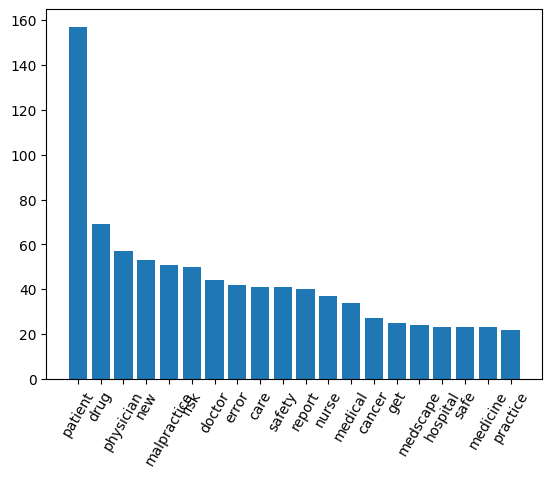

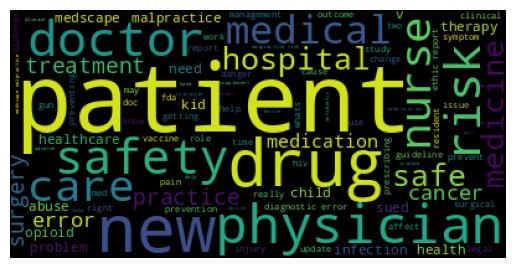

In [9]:
from collections import Counter
import matplotlib.pyplot as plt
from wordcloud import WordCloud

all_words = sum(df['cleaned'], [])
freq = Counter(all_words)

# Top 20 words
print(freq.most_common(20))

words = freq.most_common(20)
plt.bar([w[0] for w in words], [w[1] for w in words])
plt.xticks(rotation=60)
plt.show()

# Word cloud
cloud = WordCloud().generate(' '.join(all_words))
plt.imshow(cloud)
plt.axis('off')
plt.show()

In [10]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

text = df['cleaned'].apply(lambda x: ' '.join(x))

vectorizer = CountVectorizer()
X = vectorizer.fit_transform(text)

lda = LatentDirichletAllocation(n_components=5, random_state=42)
lda.fit(X)

words = vectorizer.get_feature_names_out()

for i, topic in enumerate(lda.components_):
    top_words = topic.argsort()[-5:][::-1]
    print("Topic", i + 1, ":", [words[j] for j in top_words])

Topic 1 : ['patient', 'care', 'new', 'risk', 'cancer']
Topic 2 : ['drug', 'doctor', 'new', 'patient', 'nurse']
Topic 3 : ['patient', 'report', 'malpractice', 'medscape', 'error']
Topic 4 : ['medical', 'safety', 'new', 'physician', 'malpractice']
Topic 5 : ['physician', 'surgical', 'patient', 'child', 'care']


In [11]:
!pip install pyLDAvis

import pyLDAvis
import pyLDAvis.lda_model

vis = pyLDAvis.lda_model.prepare(lda, X, vectorizer)
pyLDAvis.display(vis)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 24.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 26.4 MB/s eta 0:00:00


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
